### 1. Import library

In [1]:
#Tashfia Wahdah Fuady_202431013
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

### 2. Baca dataset, tampilkan head(), info(), dan describe()

In [2]:
#Tashfia Wahdah Fuady_202431013
data = pd.read_csv("Data Pasien penyakit liver.csv")
data.head()

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,0,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,1,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,1,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,1,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,1,3.9,2.0,195,27,59,7.3,2.4,0.40,1


In [3]:
#Tashfia Wahdah Fuady_202431013
data.info()
data.describe()

<class 'pandas.DataFrame'>
RangeIndex: 579 entries, 0 to 578
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         579 non-null    int64  
 1   Gender                      579 non-null    int64  
 2   Total_Bilirubin             579 non-null    float64
 3   Direct_Bilirubin            579 non-null    float64
 4   Alkaline_Phosphotase        579 non-null    int64  
 5   Alamine_Aminotransferase    579 non-null    int64  
 6   Aspartate_Aminotransferase  579 non-null    int64  
 7   Total_Protiens              579 non-null    float64
 8   Albumin                     579 non-null    float64
 9   Albumin_and_Globulin_Ratio  579 non-null    float64
 10  Dataset                     579 non-null    int64  
dtypes: float64(5), int64(6)
memory usage: 49.9 KB


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
count,579.000000,579.000000,579.000000,579.000000,579.000000,579.000000,579.000000,579.000000,579.000000,579.000000,579.000000
mean,44.782383,0.758204,3.315371,1.494128,291.366149,81.126079,110.414508,6.481693,3.138515,0.947064,1.284974
std,16.221786,0.428542,6.227716,2.816499,243.561863,183.182845,289.850034,1.084641,0.794435,0.319592,0.451792
min,4.000000,0.000000,0.400000,0.100000,63.000000,10.000000,10.000000,2.700000,0.900000,0.300000,1.000000
25%,33.000000,1.000000,0.800000,0.200000,175.500000,23.000000,25.000000,5.800000,2.600000,0.700000,1.000000
50%,45.000000,1.000000,1.000000,0.300000,208.000000,35.000000,42.000000,6.600000,3.100000,0.930000,1.000000
75%,58.000000,1.000000,2.600000,1.300000,298.000000,61.000000,87.000000,7.200000,3.800000,1.100000,2.000000
max,90.000000,1.000000,75.000000,19.700000,2110.000000,2000.000000,4929.000000,9.600000,5.500000,2.800000,2.000000


### 3. Periksa target dan kelasnya

In [4]:
#Tashfia Wahdah Fuady_202431013
# Keterangan kelas:
# 1 = Pasien dengan penyakit liver
# 2 = Pasien tanpa penyakit liver

data["Dataset"].value_counts()

Dataset
1    414
2    165
Name: count, dtype: int64

### 4. Bersihkan dan siapkan data

In [5]:
#Tashfia Wahdah Fuady_202431013
data.isna().sum()

df_clean = data.copy()
for col in df_clean.columns:
    if df_clean[col].isna().sum() > 0:
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

df_clean.isna().sum()

Age                           0
Gender                        0
Total_Bilirubin               0
Direct_Bilirubin              0
Alkaline_Phosphotase          0
Alamine_Aminotransferase      0
Aspartate_Aminotransferase    0
Total_Protiens                0
Albumin                       0
Albumin_and_Globulin_Ratio    0
Dataset                       0
dtype: int64

### 5. Pisahkan fitur (X) dan target (y), lalu split data (test_size=0.25, random_state=0, stratify=y)

In [6]:
#Tashfia Wahdah Fuady_202431013
X = df_clean.drop(columns=["Dataset"])
y = df_clean["Dataset"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0, stratify=y
)

pd.DataFrame({
    "Set": ["Data Latih", "Data Uji"],
    "Jumlah": [len(X_train), len(X_test)]
})

,Set,Jumlah
0,Data Latih,434
1,Data Uji,145


### 6. Periksa rentang fitur pada data latih (min dan max)

In [7]:
#Tashfia Wahdah Fuady_202431013
pd.DataFrame({
    "Min": X_train.min(),
    "Max": X_train.max(),
    "Rentang": X_train.max() - X_train.min()
})

,Min,Max,Rentang
Age,4.0,90.0,86.0
Gender,0.0,1.0,1.0
Total_Bilirubin,0.4,75.0,74.6
Direct_Bilirubin,0.1,19.7,19.6
Alkaline_Phosphotase,63.0,1896.0,1833.0
Alamine_Aminotransferase,10.0,1680.0,1670.0
Aspartate_Aminotransferase,10.0,1600.0,1590.0
Total_Protiens,2.7,9.5,6.8
Albumin,0.9,5.5,4.6
Albumin_and_Globulin_Ratio,0.3,2.8,2.5


### 7. Buat pipeline berisi StandardScaler dan KNeighborsClassifier

In [8]:
#Tashfia Wahdah Fuady_202431013
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

### 8. Pilih k dengan GridSearchCV (k = 1 sampai 19) pada data latih saja

In [9]:
#Tashfia Wahdah Fuady_202431013
param_grid = {"knn__n_neighbors": list(range(1, 20))}
grid = GridSearchCV(pipe, param_grid=param_grid, cv=5, scoring="accuracy")
grid.fit(X_train, y_train)

pd.DataFrame({
    "k Terbaik": [grid.best_params_["knn__n_neighbors"]],
    "Skor CV Terbaik": [grid.best_score_]
})

,k Terbaik,Skor CV Terbaik
0,18,0.693585


### 9. Latih model akhir dengan k terbaik dan prediksi data uji

In [10]:
#Tashfia Wahdah Fuady_202431013
best_knn = grid.best_estimator_
y_pred = best_knn.predict(X_test)

### 10. Evaluasi pada data uji

In [11]:
#Tashfia Wahdah Fuady_202431013
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

display(pd.DataFrame(
    confusion_matrix(y_test, y_pred),
    index=["Aktual 1", "Aktual 2"],
    columns=["Prediksi 1", "Prediksi 2"]))

display(pd.DataFrame(
    classification_report(y_test, y_pred, output_dict=True)).transpose())

Accuracy: 0.6828


,Prediksi 1,Prediksi 2
Aktual 1,95,9
Aktual 2,37,4


,precision,recall,f1-score,support
1,0.719697,0.913462,0.805085,104.000000
2,0.307692,0.097561,0.148148,41.000000
accuracy,0.682759,0.682759,0.682759,0.682759
macro avg,0.513695,0.505511,0.476616,145.000000
weighted avg,0.603199,0.682759,0.619330,145.000000


### 11. Uji satu data baru (nilai di dalam rentang min-max data latih)

In [12]:
#Tashfia Wahdah Fuady_202431013
data_baru = pd.DataFrame([{
    "Age": 45,
    "Gender": 1,
    "Total_Bilirubin": 1.2,
    "Direct_Bilirubin": 0.4,
    "Alkaline_Phosphotase": 210,
    "Alamine_Aminotransferase": 35,
    "Aspartate_Aminotransferase": 40,
    "Total_Protiens": 6.8,
    "Albumin": 3.5,
    "Albumin_and_Globulin_Ratio": 1.1
}])
data_baru["Prediksi_Dataset"] = best_knn.predict(data_baru)
data_baru

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Prediksi_Dataset
0,45,1,1.2,0.4,210,35,40,6.8,3.5,1.1,1


### 12. Visualisasi (opsional): grafik skor validasi silang terhadap nilai k

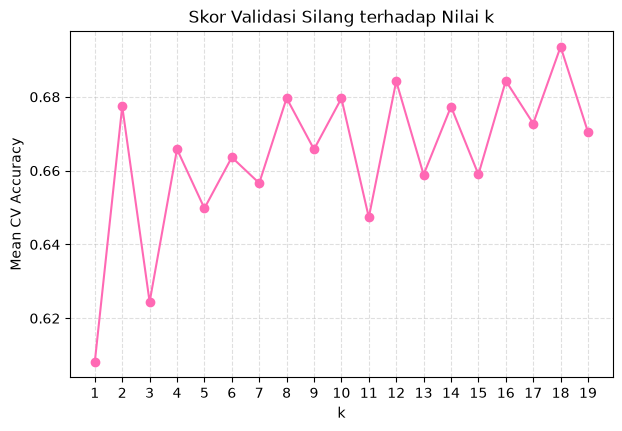

In [13]:
#Tashfia Wahdah Fuady_202431013
plt.figure(figsize=(7, 4.5))
plt.plot(range(1, 20), grid.cv_results_["mean_test_score"], marker="o", color="#ff69b4")
plt.title("Skor Validasi Silang terhadap Nilai k")
plt.xlabel("k")
plt.ylabel("Mean CV Accuracy")
plt.xticks(range(1, 20))
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()